# 1. Importar todas las librerías necesarias. (+0.15 puntos)


In [ ]:
import random
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Inicializar algunas variables que después modificaremos. (+0.15 puntos)

In [ ]:
hostnames = []
dataset = []
df = None

# 3. Crear una función para generar los hostnames en base a unas reglas.(+1.5 puntos)

In [ ]:
def set_hostnames(number_of_hosts: int) ->None:
  os = ['L']*40 + ['S']*30 + ['A']*20 + ['H']*10  #40% Linux | 30% Solaris | 20% AIX | 10% HP-UX
  environment = ['D']*10 + ['I']*10 + ['T']*25 + ['S']*25 + ['P']*30   #10% Development | 10% Integration | 25% Testing | 25% Staging | 30% Production
  country = ['NOR']*6 + ['FRA']*9 + ['ITA']*16 + ['ESP']*16 + ['DEU']*23 + ['IRL']*30  #6% Norway | 9% France | 16% Italy | 16% Spain | 23% Germany | 30% Ireland
  grupo_alpha = []   #Para controlar la parte alfabética

  for i in range(number_of_hosts):
    hostname = random.choice(os) + random.choice(environment) + random.choice(country)
    grupo_alpha.append(hostname)
    hostname += str(grupo_alpha.count(hostname)).zfill(3)    #zfill(3) -- que le meta un número de 3 digitos
    hostnames.append(hostname)

# 4. Crear una función para obtener el nombre del SO. (+0.5 puntos)

In [ ]:
def get_os(hostname: str) -> str:
  if hostname.startswith('L'):
    return 'Linux'
  elif hostname.startswith('S'):
    return 'Solaris'
  elif hostname.startswith('A'):
    return 'AIX'
  elif hostname.startswith('H'):
    return 'HP-UX'
  else:
    return 'Unknow'

# 5. Crear una función para obtener el nombre del entorno. (+0.5 puntos)

In [ ]:
def get_environment(hostname: str) -> str:
  environment = hostname[1]

  if environment == 'D':
    return 'Development'
  elif environment == 'I':
    return 'Integration'
  elif environment == 'T':
    return 'Testing'
  elif environment == 'S':
    return 'Staging'
  elif environment == 'P':
    return 'Production'
  else:
    return 'Unknow'

# 6. Crear una función para obtener el nombre del país. (+0.5 puntos)

In [ ]:
def get_country(hostname: str) -> str:
  country = hostname [2:5]

  if country == 'NOR':
    return 'Norway'
  elif country == 'FRA':
    return 'France'
  elif country == 'ITA':
    return 'Italy'
  elif country == 'ESP':
    return 'Spain'
  elif country == 'DEU':
    return 'Germany'
  elif country == 'IRL':
    return 'Ireland'
  else:
    return 'Unknow'

# 7. Crear una función para generar el DataFrame. (+1 punto)

In [ ]:
def set_dataframe(count: int) -> None:
  global df
  global hostnames
  global dataset

  hostnames = []
  dataset = []

  set_hostnames(count)

  for codigo in hostnames:
    dataset.append({
        'hostname': codigo,
        'os': get_os(codigo),
        'environment': get_environment(codigo),
        'country': get_country(codigo),
        'node': int(codigo[-3:])   #Los 3 últimos caracteres
      })

df = pd.DataFrame(dataset)
df

,hostname,os,environment,country,node
0,LSIRL001,Linux,Staging,Ireland,1
1,SDIRL001,Solaris,Development,Ireland,1
2,LTESP001,Linux,Testing,Spain,1
3,LSIRL002,Linux,Staging,Ireland,2
4,LSIRL003,Linux,Staging,Ireland,3
...,...,...,...,...,...
1495,LSFRA015,Linux,Staging,France,15
1496,AIIRL013,AIX,Integration,Ireland,13
1497,STFRA013,Solaris,Testing,France,13
1498,SIFRA007,Solaris,Integration,France,7


# 8. Crear el DataFrame. (+0.2 puntos)

In [ ]:
set_dataframe(1500)
df

,hostname,os,environment,country,node
0,LSIRL001,Linux,Staging,Ireland,1
1,SDIRL001,Solaris,Development,Ireland,1
2,LTESP001,Linux,Testing,Spain,1
3,LSIRL002,Linux,Staging,Ireland,2
4,LSIRL003,Linux,Staging,Ireland,3
...,...,...,...,...,...
1495,LSFRA015,Linux,Staging,France,15
1496,AIIRL013,AIX,Integration,Ireland,13
1497,STFRA013,Solaris,Testing,France,13
1498,SIFRA007,Solaris,Integration,France,7


# 9. Guardar el DataFrame generado en un fichero CSV. (+0.5 puntos)

In [ ]:
df.to_csv(
    'hosts.csv',
    header=True,
    index=False  #No guarde los indices
)

df_hosts = pd.read_csv('hosts.csv')
df_hosts

,hostname,os,environment,country,node
0,LSIRL001,Linux,Staging,Ireland,1
1,SDIRL001,Solaris,Development,Ireland,1
2,LTESP001,Linux,Testing,Spain,1
3,LSIRL002,Linux,Staging,Ireland,2
4,LSIRL003,Linux,Staging,Ireland,3
...,...,...,...,...,...
1495,LSFRA015,Linux,Staging,France,15
1496,AIIRL013,AIX,Integration,Ireland,13
1497,STFRA013,Solaris,Testing,France,13
1498,SIFRA007,Solaris,Integration,France,7


# 10.Generar un único gráfico, agrupando para cada país (country) los entornos (environment). (+0.5 puntos)

<Axes: xlabel='country'>

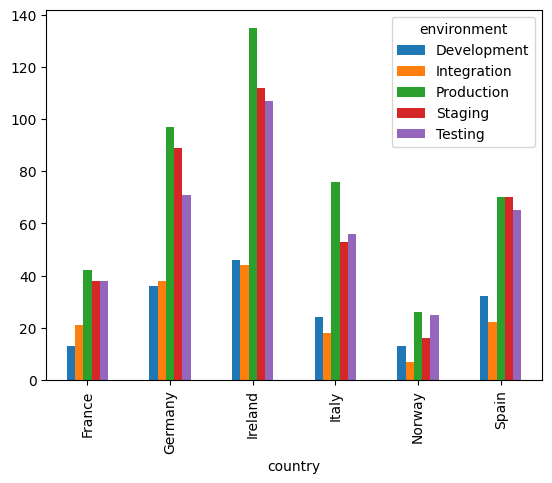

In [ ]:
g = df.groupby(['country', 'environment']).size()
g.unstack().plot(kind='bar')

# 11.Crear una figura con 4 gráficos en una malla de 2 filas y 2 columnas. (+4.5 puntos)

In [ ]:
#Gráfico 1
os_country = df.groupby(['country', 'os']).size()
os_country

country  os     
France   AIX         37
         HP-UX        8
         Linux       57
         Solaris     50
Germany  AIX         70
         HP-UX       24
         Linux      147
         Solaris     90
Ireland  AIX         88
         HP-UX       48
         Linux      163
         Solaris    145
Italy    AIX         42
         HP-UX       24
         Linux       88
         Solaris     73
Norway   AIX         15
         HP-UX       11
         Linux       35
         Solaris     26
Spain    AIX         46
         HP-UX       32
         Linux      102
         Solaris     79
dtype: int64

In [ ]:
#Gráfico 1
os_country.unstack()

os,AIX,HP-UX,Linux,Solaris
country,,,,
France,37,8,57,50
Germany,70,24,147,90
Ireland,88,48,163,145
Italy,42,24,88,73
Norway,15,11,35,26
Spain,46,32,102,79


In [ ]:
#Gráfico 2
os_counts = df.groupby(['os']).size()
os_counts

,0
os,
AIX,298
HP-UX,147
Linux,592
Solaris,463


In [ ]:
#Grágico 2
percentages = (os_counts / os_counts.sum()) * 100
legend_labels = [f"{os}: {p:.1f}%" for os, p in zip(os_counts.index, percentages)]

In [ ]:
#Gráfico 3
country_counts = df['country'].value_counts()
country_counts


,count
country,
Ireland,444
Germany,331
Spain,259
Italy,227
France,152
Norway,87


In [ ]:
#Gráfico 3
x_max = country_counts.max() + 100 #Máximo + 100 en el eje x

colors = sns.color_palette('Greens_r', len(country_counts)) #color del gráfico

In [ ]:
#Gráfico 4
country_environment = df.groupby(['country', 'environment']).size()
country_environment

country  environment
France   Development     13
         Integration     21
         Production      42
         Staging         38
         Testing         38
Germany  Development     36
         Integration     38
         Production      97
         Staging         89
         Testing         71
Ireland  Development     46
         Integration     44
         Production     135
         Staging        112
         Testing        107
Italy    Development     24
         Integration     18
         Production      76
         Staging         53
         Testing         56
Norway   Development     13
         Integration      7
         Production      26
         Staging         16
         Testing         25
Spain    Development     32
         Integration     22
         Production      70
         Staging         70
         Testing         65
dtype: int64

In [ ]:
#Gráfico 4
country_environment.unstack(0)

country,France,Germany,Ireland,Italy,Norway,Spain
environment,,,,,,
Development,13,36,46,24,13,32
Integration,21,38,44,18,7,22
Production,42,97,135,76,26,70
Staging,38,89,112,53,16,70
Testing,38,71,107,56,25,65


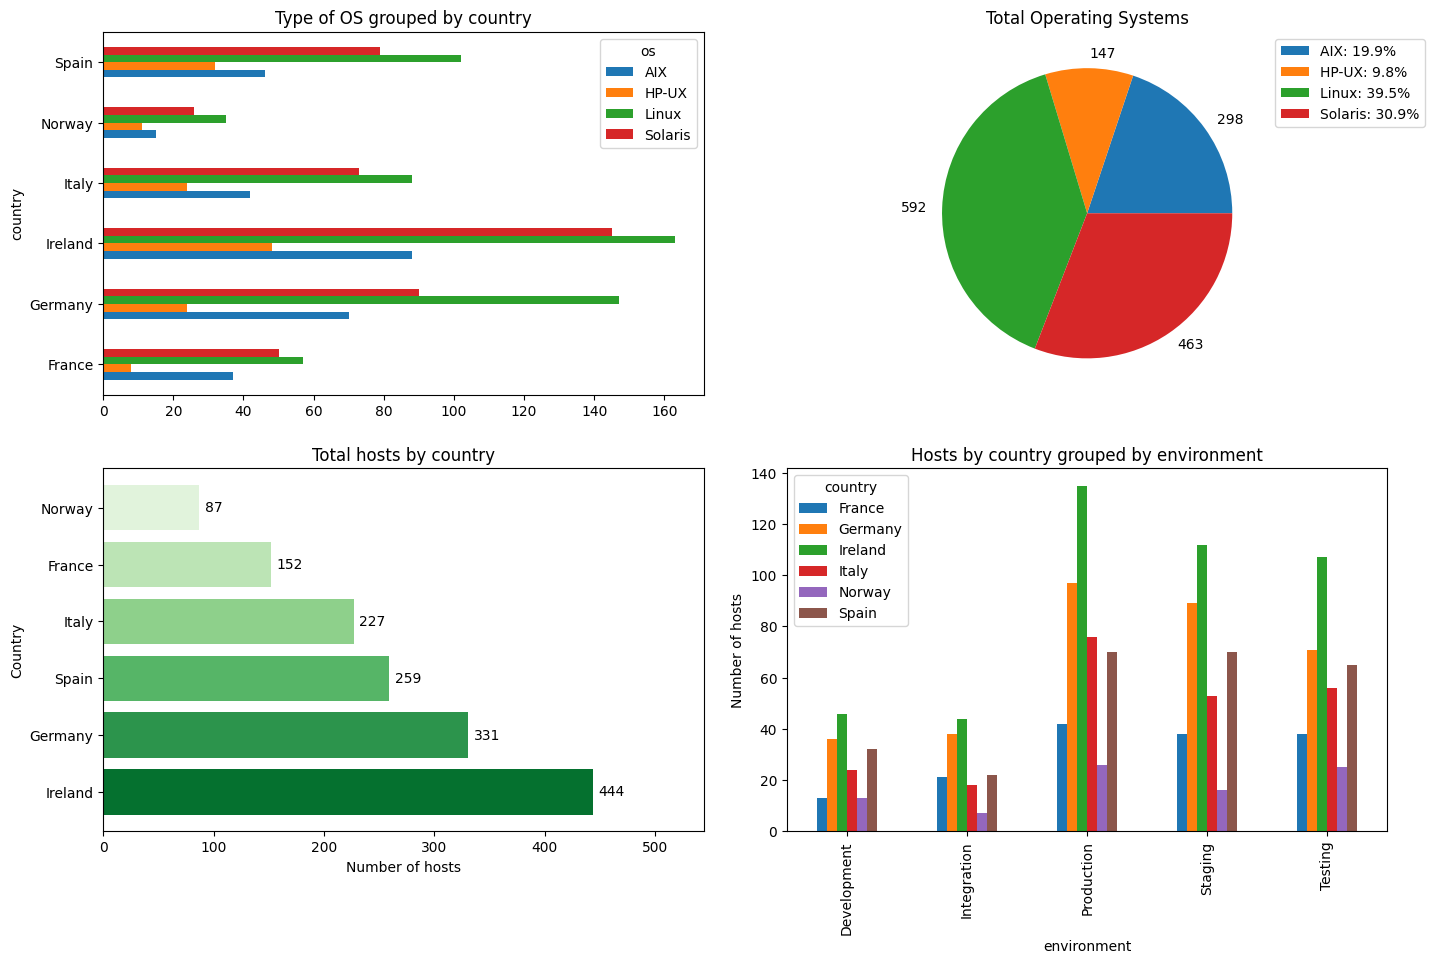

In [ ]:
fig, axs = plt.subplots(2, 2, figsize=(15,10))

#Gráfico 1
os_country.unstack().plot(kind='barh', ax=axs[0, 0])
axs[0, 0].set_title('Type of OS grouped by country')

#Gráfico 2
axs[0,1].pie(os_counts.values, labels = os_counts.values)
axs[0,1].set_title('Total Operating Systems')
axs[0,1].legend(
    legend_labels,
    loc='upper left',
    bbox_to_anchor = (1.0, 1.0)
)

#Gráfico 3
axs[1,0].barh(country_counts.index, country_counts.values, color=colors)
axs[1,0].set_title('Total hosts by country')

axs[1,0].set_xlabel('Number of hosts') #Etiquetas
axs[1,0].set_ylabel('Country')

axs[1,0].set_xlim(0, x_max) #Límite máximo del eje x

for i, v in enumerate(country_counts.values): #Número de hosts a la derecha de las barras
  axs[1,0].text(v + 5,
                  i,
                  str(v),
                  va='center')

#Gráfico 4
country_environment.unstack(0).plot(kind = 'bar', ax=axs[1,1])
axs[1,1].set_title('Hosts by country grouped by environment')

axs[1,1].set_ylabel('Number of hosts') #Etiqueta

fig.tight_layout(pad=2.0)



